# Vapour-Liquid Equilibrium -. Example: ternary mixture acetone-methanol-water

Speration processes that involves gas phase and liquid phase are governed by vapour-liquid equilibrium.

There are three cases of VLE problems:
* Bubble-point T calculation: Given liquid composition (xi) and pressure (P), determine the equilibrium temperature (T),
* Bubble-point P calculation: Given liquid composition (xi) and temperature (T), determine the equilibrium pressure (P),
* Dew-point T calculation: Given vapor composition (yi) and pressure (P), determine the equilibrium temperature (T),
* Dew-point P calculation: Given vapor composition (yi) and temperature (T), determine the equilibrium pressure (P).

In our applications, we usually assume the pressure to be constant, and then we can either either perform a bubble-T or a dew-T calculation. We will go ahead with bubble-T.

The governing set of conditions for the VLE are therefore:

1. VLE condition: Fugacities of each component must be equal in vapor and liquid phases
2. Ideal vapor assumption: Vapor phase fugacity coefficient = 1, simplifying the equilibrium
3. Bubble point formulation: Given liquid composition, solve for temperature and vapor composition
4. Degrees of freedom: With fixed pressure and given liquid composition, the system has 2 unknowns (T and vapor fractions) and 2 equations. However since these two are related (given T, y can be calculated and vice-versa, only one degree of freedom is present, e.g. the temperature)


Fugacity equality (general VLE condition):
\begin{equation*}
\hat{f}_i^V = \hat{f}_i^L
\end{equation*}

Vapor phase fugacity:
\begin{equation*}
\hat{f}_i^V = y_i \hat{\phi}_i P
\end{equation*}

Liquid phase fugacity:
\begin{equation*}
\hat{f}_i^L = x_i \hat{\gamma}_i P_i^{sat}
\end{equation*}

VLE equilibrium (ideal vapor phase):
\begin{equation*}
y_i = x_i \hat{\gamma}_i \frac{P_i^{sat}}{P}
\end{equation*}

Vapor composition normalization:
\begin{equation*}
\sum_i y_i = 1
\end{equation*}



Let us try the complete workflow:
1. define e.g. acetone-methanol system
2. calculate the pure component properties
3. determine the Antoine coefficients
4. perform the VLE routine

In [27]:
# imports to enable the notebook to access the src folder
import sys
import os
sys.path.append(os.path.dirname(os.getcwd()))

# import the necessary packages
from src.molecules import StructuralValidator
from src.pure import PropertyCalculator
from src.pure import AntoineCalculator
from src.data import load_unifac_data
from src.mixture.unifac.pyomo_vle import pyo_vle
import numpy as np
import matplotlib.pyplot as plt


In [28]:
# step1: define the compounds
mixture = {'acetone': {'CH3':1, 'CH3CO':1},
           #'methanol': {'CH3OH':1},
           'n-heptane': {'CH3':2, 'CH2':5},
           #'water': {'H2O':1}
           #'E': {'CH2': 3, 'HCO': 1, 'CH3COO': 1}
           #'E': {'CH2':1, 'HCO':2}
           #'E': {'CH3':1, 'CH2':2, 'CH3CO':1, 'CH2O':1}
           #'E': {'CH3':3, 'CH':1, 'CH2COO':1}
           }
# validate the structures
validator = StructuralValidator()
validator.validate(mixture)

{'acetone': True, 'n-heptane': True}

In [29]:
# step2: calculate the required properties
prop_list = ['tc', 'pc', 'tb', 'ac', 'hv']
pure_calc = PropertyCalculator()
pure_props = pure_calc.calculate(mixture, prop_list)
# fix the properties of acetone
pure_props['acetone']['tc'] = 508.1
pure_props['acetone']['pc'] = 48.0
pure_props['acetone']['tb'] = 329.3
pure_props

{'acetone': {'tc': 508.1,
  'pc': 48.0,
  'tb': 329.3,
  'ac': 0.33226923286882887,
  'hv': 29.944},
 'n-heptane': {'tc': 549.8559805147336,
  'pc': 28.26756251167203,
  'tb': 379.0732115086755,
  'ac': 0.3368237739045966,
  'hv': 38.311}}

In [30]:
# step3: calculate the Antoine coefficients
antoine_params = {}
antoine_calc = AntoineCalculator()
for compound, props in pure_props.items():
    results = antoine_calc.calculate_antoine_parameters(mixture, critical_properties=props, method='enthalpy_vap')
    print('optimization results was', results['termination_condition'] )
    antoine_params[compound] = {}
    # antoine_params_ini[compound]['A'] = results['A0']
    # antoine_params_ini[compound]['B'] = results['B0']
    # antoine_params_ini[compound]['C'] = results['C0']
    antoine_params[compound]['A'] = results['A']
    antoine_params[compound]['B'] = results['B']
    antoine_params[compound]['C'] = results['C']
print(antoine_params)

optimization results was optimal
optimization results was optimal
{'acetone': {'A': 4.783740729661747, 'B': 1581.8917318530048, 'C': 1.7765481786898079}, 'n-heptane': {'A': 4.087652923814033, 'B': 1271.3820873048353, 'C': -67.60777199311146}}


In [31]:
# step4: perform the vle

# define number of data points
n_data = 100
# set composition
# generate all binary combinations for ternary system
# x1-x2 binary (x3=0)
x0 = 0.0
xf = 1-x0
x1_12 = np.linspace(x0, xf, n_data)
x2_12 = 1 - x1_12
if len(mixture.keys()) == 3:
    x3_12 = np.zeros(n_data)

if len(mixture.keys()) == 3:
    # x1-x3 binary (x2=0)
    x1_13 = np.linspace(x0, xf, n_data)
    x2_13 = np.zeros(n_data)
    x3_13 = 1 - x1_13

    # x2-x3 binary (x1=0)
    x1_23 = np.zeros(n_data)
    x2_23 = np.linspace(x0, xf, n_data)
    x3_23 = 1 - x2_23

# combine all binary combinations
if len(mixture.keys()) == 2:
    x = np.column_stack([x1_12, x2_12])
elif len(mixture.keys()) == 3:
    x = np.vstack([
        np.column_stack([x1_12, x2_12, x3_12]),
        np.column_stack([x1_13, x2_13, x3_13]),
        np.column_stack([x1_23, x2_23, x3_23])
    ])
# provide nitial guess for temperature

# Extract boiling points for each compound
tb_values = [pure_props[compound]['tb'] for compound in mixture.keys()]
if len(mixture.keys()) == 3:
    tb1, tb2, tb3 = tb_values  # assuming 3 components
elif len(mixture.keys()) == 2:
    tb1, tb2 = tb_values  # assuming 2 components
# Create T0 for each binary combination
# x1-x2 binary: T ranges from tb2 (x1=0, x2=1) to tb1 (x1=1, x2=0)
T0_12 = np.linspace(tb2, tb1, n_data)

if len(mixture.keys()) == 3:
    # x1-x3 binary: T ranges from tb3 (x1=0, x3=1) to tb1 (x1=1, x3=0)
    T0_13 = np.linspace(tb3, tb1, n_data)

    # x2-x3 binary: T ranges from tb3 (x2=0, x3=1) to tb2 (x2=1, x3=0)
    T0_23 = np.linspace(tb3, tb2, n_data)

# Combine all T0 values
if len(mixture.keys()) == 3:
    T0 = np.concatenate([T0_12, T0_13, T0_23])
elif len(mixture.keys()) == 2:
    T0 = T0_12
# Load all UNIFAC parameters
rk_data, qk_data, interaction_data = load_unifac_data()
# perform the VLE calculation
results, model = pyo_vle(x, T0, mixture, rk_data, qk_data, interaction_data, antoine_params, verbose=True)


Ipopt 3.14.13: halt_on_ampl_error=yes
max_iter=100000
tol=1e-06


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************

This is Ipopt version 3.14.13, running with linear solver MUMPS 5.2.1.

Number of nonzeros in equality constraint Jacobian...:    13298
Number of nonzeros in inequality constraint Jacobian.:        0
Number of nonzeros in Lagrangian Hessian.............:    11210

Total number of variables............................:     3610
                     variables with only lower bounds:     2910
                variables with lower and upper bounds:      300
                     variables with only upper bounds:        0
Total number of equality co

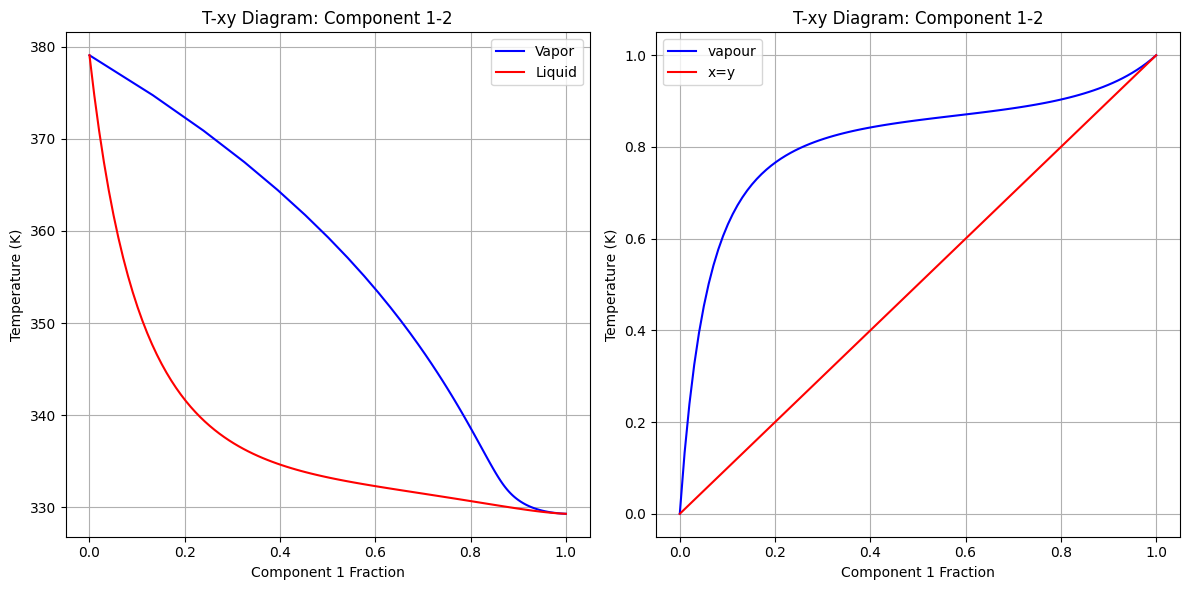

In [36]:
# step5: lets plot the results in T-xy diagram and inspect the gamma values
import matplotlib.pyplot as plt

# Extract results
# retrieving the solutions
gamma_pyo = np.empty_like(x)
T_pyo = np.empty_like(T0)
y_pyo = np.empty_like(x)
psat_pyo = np.empty_like(x)

for i in model.gamma.keys():
    gamma_pyo[i] = model.gamma[i].value

for i in model.T.keys():
    T_pyo[i] = model.T[i].value

for i in model.y.keys():
    y_pyo[i] = model.y[i].value

for i in model.psat.keys():
    psat_pyo[i] = model.psat[i].value

# Create T-xy plots for all three binary combinations
if len(mixture.keys()) == 3:
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
elif len(mixture.keys()) == 2:
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Component 1-2 diagram (first 100 points)
axes[0].plot(y_pyo[:n_data, 0], T_pyo[:n_data], 'b-', label='Vapor')
axes[0].plot(x[:n_data, 0], T_pyo[:n_data], 'r-', label='Liquid')
axes[0].set_ylabel('Temperature (K)')
axes[0].set_xlabel('Component 1 Fraction')
axes[0].set_title('T-xy Diagram: Component 1-2')
axes[0].legend()
axes[0].grid()

if len(mixture.keys()) == 2:
    axes[1].plot(x[:n_data, 0], y_pyo[:n_data, 0], 'b-', label='vapour')
    axes[1].plot(x[:n_data, 0], x[:n_data, 0], 'r-', label='x=y')
    axes[1].set_ylabel('Temperature (K)')
    axes[1].set_xlabel('Component 1 Fraction')
    axes[1].set_title('T-xy Diagram: Component 1-2')
    axes[1].legend()
    axes[1].grid()

if len(mixture.keys()) == 3:
    # Component 1-3 diagram (points 100-200)
    axes[1].plot(y_pyo[n_data:2*n_data, 0], T_pyo[n_data:2*n_data], 'b-', label='Vapor')
    axes[1].plot(x[n_data:2*n_data, 0], T_pyo[n_data:2*n_data], 'r-', label='Liquid')
    axes[1].set_ylabel('Temperature (K)')
    axes[1].set_xlabel('Component 1 Fraction')
    axes[1].set_title('T-xy Diagram: Component 1-3')
    axes[1].legend()
    axes[1].grid()

    # Component 2-3 diagram (points 200-300)
    axes[2].plot(y_pyo[2*n_data:3*n_data, 1], T_pyo[2*n_data:3*n_data], 'b-', label='Vapor')
    axes[2].plot(x[2*n_data:3*n_data, 1], T_pyo[2*n_data:3*n_data], 'r-', label='Liquid')
    axes[2].set_ylabel('Temperature (K)')
    axes[2].set_xlabel('Component 2 Fraction')
    axes[2].set_title('T-xy Diagram: Component 2-3')
    axes[2].legend()
    axes[2].grid()

plt.tight_layout()
plt.show()

# 

we will now make a test for the azeotrope detection according to the following equations.

\begin{equation*}
\log \gamma_A \cdot P_A^{\text{sat}}\big|_{x_A=0} - \log \gamma_B \cdot P_B^{\text{sat}}\big|_{x_A=1}
\end{equation*}

lets check the charachtertic points of the vle

In [37]:
x[[0, n_data-1,n_data]]

IndexError: index 100 is out of bounds for axis 0 with size 100

In [ ]:
# is there azeotrope between acetone and methanol?
print(f"there is azeotrope between acetone and methanol: {np.log(gamma_pyo[0,0]*psat_pyo[0,0]) * (- np.log(gamma_pyo[n_data-1,1]*psat_pyo[n_data-1,1])) }")
print(f"there is azeotrope between acetone and water: {np.log(gamma_pyo[-1,0]*psat_pyo[-1,0]) * (- np.log(gamma_pyo[n_data-1,2]*psat_pyo[n_data-1,2])) }")
print(f"there is azeotrope between methanol and water: {np.log(gamma_pyo[-1,1]*psat_pyo[-1,1]) * (- np.log(gamma_pyo[0,2]*psat_pyo[0,2])) }")

there is azeotrope between acetone and methanol: 5.0143698660434595
there is azeotrope between acetone and water: -0.6407397938227513
there is azeotrope between methanol and water: -0.07812562457973475


Now lets check for the mscibility between water and the two other components according to the two relations:

\begin{equation*}
\frac{\Delta G_{\text{mix}}}{RT} = \sum_i x_i \log(\gamma_i) + \sum_i x_i \log(x_i) \leq 0
\end{equation*}

\begin{equation*}
  \frac{\partial^2 \left(\frac{\Delta G^{mix}}{RT}\right)}{\partial x_i^2} = \frac{\Delta G^{mix}}{RT}\bigg|_{x_{p+1,i}} - 2 \frac{\Delta
  G^{mix}}{RT}\bigg|_{x_{p,i}} + \frac{\Delta G^{mix}}{RT}\bigg|_{x_{p-1,i}} \geq 0
\end{equation*}

In [ ]:
# miscibility between acetone and water
Gmix = (np.sum(x * np.log(gamma_pyo), axis=1) +
                np.sum(np.ma.log(x).filled(0) * x, axis=1))
Gmix_13 = Gmix[n_data:2*n_data]
Gmix_23 = Gmix[2*n_data:]
# calculate 2nd derivatives
Gmix_13_2nd = np.diff(np.diff(Gmix_13))
Gmix_23_2nd = np.diff(np.diff(Gmix_23))
# miscibility between methanol and water
print(f"mixture of acetone and E is miscible: {np.all(Gmix_13 <= 0) and np.all(Gmix_13_2nd >= 0)}")
print(f"mixture of methanol and E is miscible: {np.all(Gmix_23 <= 0) and np.all(Gmix_23_2nd >= 0)}")

mixture of acetone and E is miscible: False
mixture of methanol and E is miscible: False


In [ ]:
Gmix_13

array([-1.43995926e-13, -3.16437476e-02, -5.01271005e-02, -6.41721206e-02,
       -7.56139329e-02, -8.53054269e-02, -9.37341674e-02, -1.01210890e-01,
       -1.07947534e-01, -1.14095512e-01, -1.19766686e-01, -1.25045812e-01,
       -1.29998360e-01, -1.34675682e-01, -1.39118537e-01, -1.43359586e-01,
       -1.47425184e-01, -1.51336719e-01, -1.55111612e-01, -1.58764078e-01,
       -1.62305731e-01, -1.65746041e-01, -1.69092711e-01, -1.72351972e-01,
       -1.75528826e-01, -1.78627238e-01, -1.81650300e-01, -1.84600361e-01,
       -1.87479140e-01, -1.90287818e-01, -1.93027112e-01, -1.95697343e-01,
       -1.98298489e-01, -2.00830233e-01, -2.03292000e-01, -2.05682992e-01,
       -2.08002216e-01, -2.10248508e-01, -2.12420553e-01, -2.14516905e-01,
       -2.16535997e-01, -2.18476157e-01, -2.20335617e-01, -2.22112520e-01,
       -2.23804932e-01, -2.25410838e-01, -2.26928157e-01, -2.28354735e-01,
       -2.29688352e-01, -2.30926724e-01, -2.32067496e-01, -2.33108247e-01,
       -2.34046484e-01, -

In [ ]:
Gmix_13[1:-1]

array([-0.03164375, -0.0501271 , -0.06417212, -0.07561393, -0.08530543,
       -0.09373417, -0.10121089, -0.10794753, -0.11409551, -0.11976669,
       -0.12504581, -0.12999836, -0.13467568, -0.13911854, -0.14335959,
       -0.14742518, -0.15133672, -0.15511161, -0.15876408, -0.16230573,
       -0.16574604, -0.16909271, -0.17235197, -0.17552883, -0.17862724,
       -0.1816503 , -0.18460036, -0.18747914, -0.19028782, -0.19302711,
       -0.19569734, -0.19829849, -0.20083023, -0.203292  , -0.20568299,
       -0.20800222, -0.21024851, -0.21242055, -0.21451691, -0.216536  ,
       -0.21847616, -0.22033562, -0.22211252, -0.22380493, -0.22541084,
       -0.22692816, -0.22835473, -0.22968835, -0.23092672, -0.2320675 ,
       -0.23310825, -0.23404648, -0.23487964, -0.23560506, -0.23622003,
       -0.23672171, -0.23710719, -0.23737342, -0.23751727, -0.23753544,
       -0.23742451, -0.23718088, -0.23680078, -0.23628024, -0.23561505,
       -0.23480076, -0.23383262, -0.23270559, -0.23141422, -0.22

In [ ]:
Gmix_13_2nd

array([1.31603946e-02, 4.43833291e-03, 2.60320772e-03, 1.75031835e-03,
       1.26275348e-03, 9.52017578e-04, 7.40079289e-04, 5.88666019e-04,
       4.76802747e-04, 3.92049491e-04, 3.26577387e-04, 2.75226195e-04,
       2.34466013e-04, 2.01807528e-04, 1.75450053e-04, 1.54062669e-04,
       1.36643330e-04, 1.22425436e-04, 1.10814251e-04, 1.01342666e-04,
       9.36397980e-05, 8.74083011e-05, 8.24077188e-05, 7.84420906e-05,
       7.53506084e-05, 7.30004898e-05, 7.12814835e-05, 7.01015931e-05,
       6.93837191e-05, 6.90629993e-05, 6.90846890e-05, 6.94024576e-05,
       6.99770119e-05, 7.07749785e-05, 7.17679894e-05, 7.29319331e-05,
       7.42463366e-05, 7.56938556e-05, 7.72598519e-05, 7.89320427e-05,
       8.07002102e-05, 8.25559602e-05, 8.44925236e-05, 8.65045924e-05,
       8.85881875e-05, 9.07405524e-05, 9.29600702e-05, 9.52462017e-05,
       9.75994433e-05, 1.00021302e-04, 1.02514287e-04, 1.05081920e-04,
       1.07728759e-04, 1.10460444e-04, 1.13283756e-04, 1.16206696e-04,
      

A final element is to caulcate the relative volatility, selecivity and capacity at infinite dilution

\begin{equation*}
\alpha_{A,B}^{\infty} = \left(\frac{K_A^{\infty}}{K_B^{\infty}}\right)_E = \left(\frac{\gamma_A^{\infty}}{P^*_A} * \frac{\gamma_B^{\infty}}{P^*_B} \right)_E  
\end{equation*}


\begin{equation*}
S_{A,B}^{\infty} = \left(\frac{\gamma_A^{\infty}}{\gamma_B^{\infty}}\right)_E
\end{equation*}

\begin{equation*}
C_{B,E}^{\infty} = \left(\frac{1}{\gamma_B^{\infty}}\right)_E
\end{equation*}

\begin{equation*}
C_{B,E}^{\infty} * S_{A,B}^{\infty}
\end{equation*}

In [ ]:
x[[0, n_data-1,n_data]]

array([[0., 1., 0.],
       [1., 0., 0.],
       [0., 0., 1.]])

In [ ]:
# calculate the relative volatility
alpha = gamma_pyo[n_data,0]/psat_pyo[n_data,0] * gamma_pyo[n_data,1]/gamma_pyo[n_data,1]
alpha

np.float64(3.426563274548982)

In [ ]:
# calculate selectivity
S = gamma_pyo[n_data,0]/gamma_pyo[n_data,1]
S

np.float64(0.000930537373227056)

In [ ]:
# calculate the capacity
C = 1/gamma_pyo[n_data,1]
C

np.float64(7.616350690963792e-05)

In [ ]:
# calculating the product
S*C

np.float64(7.087298965545519e-08)